# EMQA_L5_spreads

**Monthly clean spark and clean dark spreads**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_spreads/EMQA_L5_spreads.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Clean spark and clean dark spreads, monthly, from real power, gas, coal and carbon prices.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def legend_compact(fig, ncol):
    """Bottom legend with shorter handles and column gaps, for many short entries."""
    legend_bottom(fig, ncol=ncol)
    h, l = fig.legends[-1].legend_handles, [t.get_text() for t in fig.legends[-1].get_texts()]
    fig.legends[-1].remove()
    fig.legend(h, l, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=1.0, handletextpad=0.4, columnspacing=0.9)


def save_chart(fig, name):
    """Keep under the axes exactly the height of the bottom legend, then save the PNG."""
    fig.canvas.draw()
    bottom = max([lg.get_window_extent().height / fig.bbox.height + 0.035 for lg in fig.legends] or [0.0])
    fig.tight_layout(rect=(0, bottom, 1, 1))
    plt.savefig(name + '.png', dpi=150, bbox_inches='tight', transparent=True)
    plt.show()


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
# monthly mean day-ahead prices, kept only for months with every day present
m_idx = pd.date_range('2015-01-01', END.replace(day=1), freq='MS')
PM = PD[['RO', 'HU', 'DE_LU']].resample('MS').mean().reindex(m_idx)
NDM = PD[['RO', 'HU', 'DE_LU']].resample('MS').count().reindex(m_idx)
PM = PM.where(NDM.eq(pd.Series(m_idx.days_in_month, index=m_idx), axis=0))

In [5]:
# technical assumptions (stated on the slides)
ETA_GAS, ETA_COAL = 0.50, 0.38        # efficiency of a combined-cycle gas plant and of a hard-coal plant
EF_GAS, EF_COAL = 0.202, 0.341        # t CO2 per MWh thermal (IPCC 2006: 56.1 and 94.6 t CO2/TJ)
COAL_MWH_T = 6.978                    # MWh thermal per tonne of 6000 kcal/kg coal (6000*4.1868/3600)

# gas: TTF monthly (World Bank), EUR/MWh
TTFM = pd.read_csv(DATA + 'ttf_monthly.csv')
TTFM.index = pd.PeriodIndex(TTFM['month'], freq='M').to_timestamp()
GAS = TTFM['ttf_eur_mwh'].reindex(m_idx)
# carbon: EEX primary-auction EUA price (monthly mean); SparkChange ETC proxy after the last EEX month
EUA = pd.read_csv(DATA + 'eua_daily.csv', parse_dates=['date']).set_index('date')
eua_a = EUA['eua_eex_auction_eur_t'].dropna().resample('MS').mean()
eua_e = EUA['eua_etc_co2l_eur_per_unit'].dropna().resample('MS').mean()
EUAM = eua_a.reindex(m_idx).fillna(eua_e.reindex(m_idx).where(m_idx > eua_a.index.max()))
print('EUA: EEX auctions to', eua_a.index.max().strftime('%Y-%m'), '; ETC proxy afterwards')

EUA: EEX auctions to 2025-12 ; ETC proxy afterwards


In [6]:
# coal: World Bank South African export coal, USD/t -> EUR per MWh thermal
COAL = pd.read_csv(DATA + 'coal_monthly.csv')
COAL.index = pd.PeriodIndex(COAL['month'], freq='M').to_timestamp()
FUEL = pd.read_csv(DATA + 'fuels_daily.csv', parse_dates=['date']).set_index('date')
fxm = FUEL['eurusd_ecb'].resample('MS').mean().reindex(m_idx)
COALE = (COAL['coal_southafrica_usd_t'].reindex(m_idx) / fxm) / COAL_MWH_T


def spreads(p, gas, coal, eua):
    """Spark, clean spark, dark and clean dark spreads in EUR per MWh of electricity."""
    ss = p - gas / ETA_GAS
    css = ss - EF_GAS / ETA_GAS * eua
    ds = p - coal / ETA_COAL
    cds = ds - EF_COAL / ETA_COAL * eua
    return pd.DataFrame({'ss': ss, 'css': css, 'ds': ds, 'cds': cds})


SPR = {z: spreads(PM[z], GAS, COALE, EUAM) for z in ['RO', 'DE_LU']}
show('months with a clean spark spread', SPR['RO']['css'].notna().sum(), 'spread.n_m', 'd')
show('months with a negative clean spark spread, Romania', (SPR['RO']['css'] < 0).sum(), 'spread.css_ro_neg_m', 'd')
show('months with a negative clean spark spread, Germany', (SPR['DE_LU']['css'] < 0).sum(), 'spread.css_de_neg_m', 'd')
show('mean gap of the clean spark spread, Romania - Germany', (SPR['RO']['css'] - SPR['DE_LU']['css']).mean(), 'spread.gap_ro_de', '.2f')
show('highest clean spark spread, Romania, EUR/MWh', SPR['RO']['css'].max(), 'spread.css_ro_max', '.2f')
show('  month', SPR['RO']['css'].idxmax().strftime('%Y-%m'), 'spread.css_ro_max_ym')
show('lowest clean spark spread, Romania, EUR/MWh', SPR['RO']['css'].min(), 'spread.css_ro_min', '.2f')
show('  month', SPR['RO']['css'].idxmin().strftime('%Y-%m'), 'spread.css_ro_min_ym')
show('months where gas beats coal (CSS > CDS), Romania', (SPR['RO']['css'] > SPR['RO']['cds']).sum(), 'spread.gas_cheaper_m', 'd')
yrs = SPR['RO'].groupby(SPR['RO'].index.year).mean()
for y in yrs.index:
    show(f'{y}: mean clean spark / clean dark spread, Romania', f"{yrs.loc[y, 'css']:.2f} / {yrs.loc[y, 'cds']:.2f}")

months with a clean spark spread                                    138   [spread.n_m]
months with a negative clean spark spread, Romania                   67   [spread.css_ro_neg_m]
months with a negative clean spark spread, Germany                  121   [spread.css_de_neg_m]
mean gap of the clean spark spread, Romania - Germany             13.95   [spread.gap_ro_de]
highest clean spark spread, Romania, EUR/MWh                      53.01   [spread.css_ro_max]
  month                                                         2024-07   [spread.css_ro_max_ym]
lowest clean spark spread, Romania, EUR/MWh                      -92.93   [spread.css_ro_min]
  month                                                         2022-10   [spread.css_ro_min_ym]
months where gas beats coal (CSS > CDS), Romania                     48   [spread.gas_cheaper_m]
2015: mean clean spark / clean dark spread, Romania        -10.83 / 8.99
2016: mean clean spark / clean dark spread, Romania         2.79 / 6.55
2017

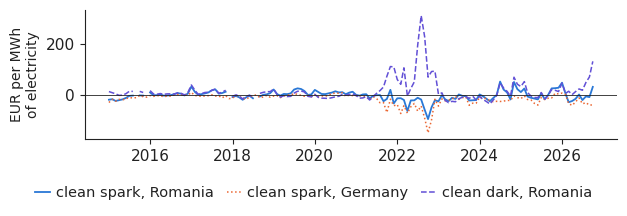

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 2.2))
ax.plot(SPR['RO'].index, SPR['RO']['css'], color=PAL['RO'], lw=1.3, label='clean spark, Romania')
ax.plot(SPR['DE_LU'].index, SPR['DE_LU']['css'], color=PAL['DE_LU'], lw=1.1, ls=':', label='clean spark, Germany')
ax.plot(SPR['RO'].index, SPR['RO']['cds'], color=PAL['c7'], lw=1.1, ls='--', label='clean dark, Romania')
ax.axhline(0, color='#222222', lw=0.6)
ax.set_ylabel('EUR per MWh\nof electricity', fontsize=10)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
legend_compact(fig, ncol=3)
save_chart(fig, 'spreads')